In [1]:
# Research review: Run from the project root after restoring approved tables to their original filenames. The organized data originals are in data/tables.
import pandas as pd
df=pd.read_csv('desalination.csv')

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use('default')

mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.size'] = 12
mpl.rcParams['axes.labelsize'] = 13
mpl.rcParams['axes.titlesize'] = 15
mpl.rcParams['legend.fontsize'] = 11

# Load Dataset


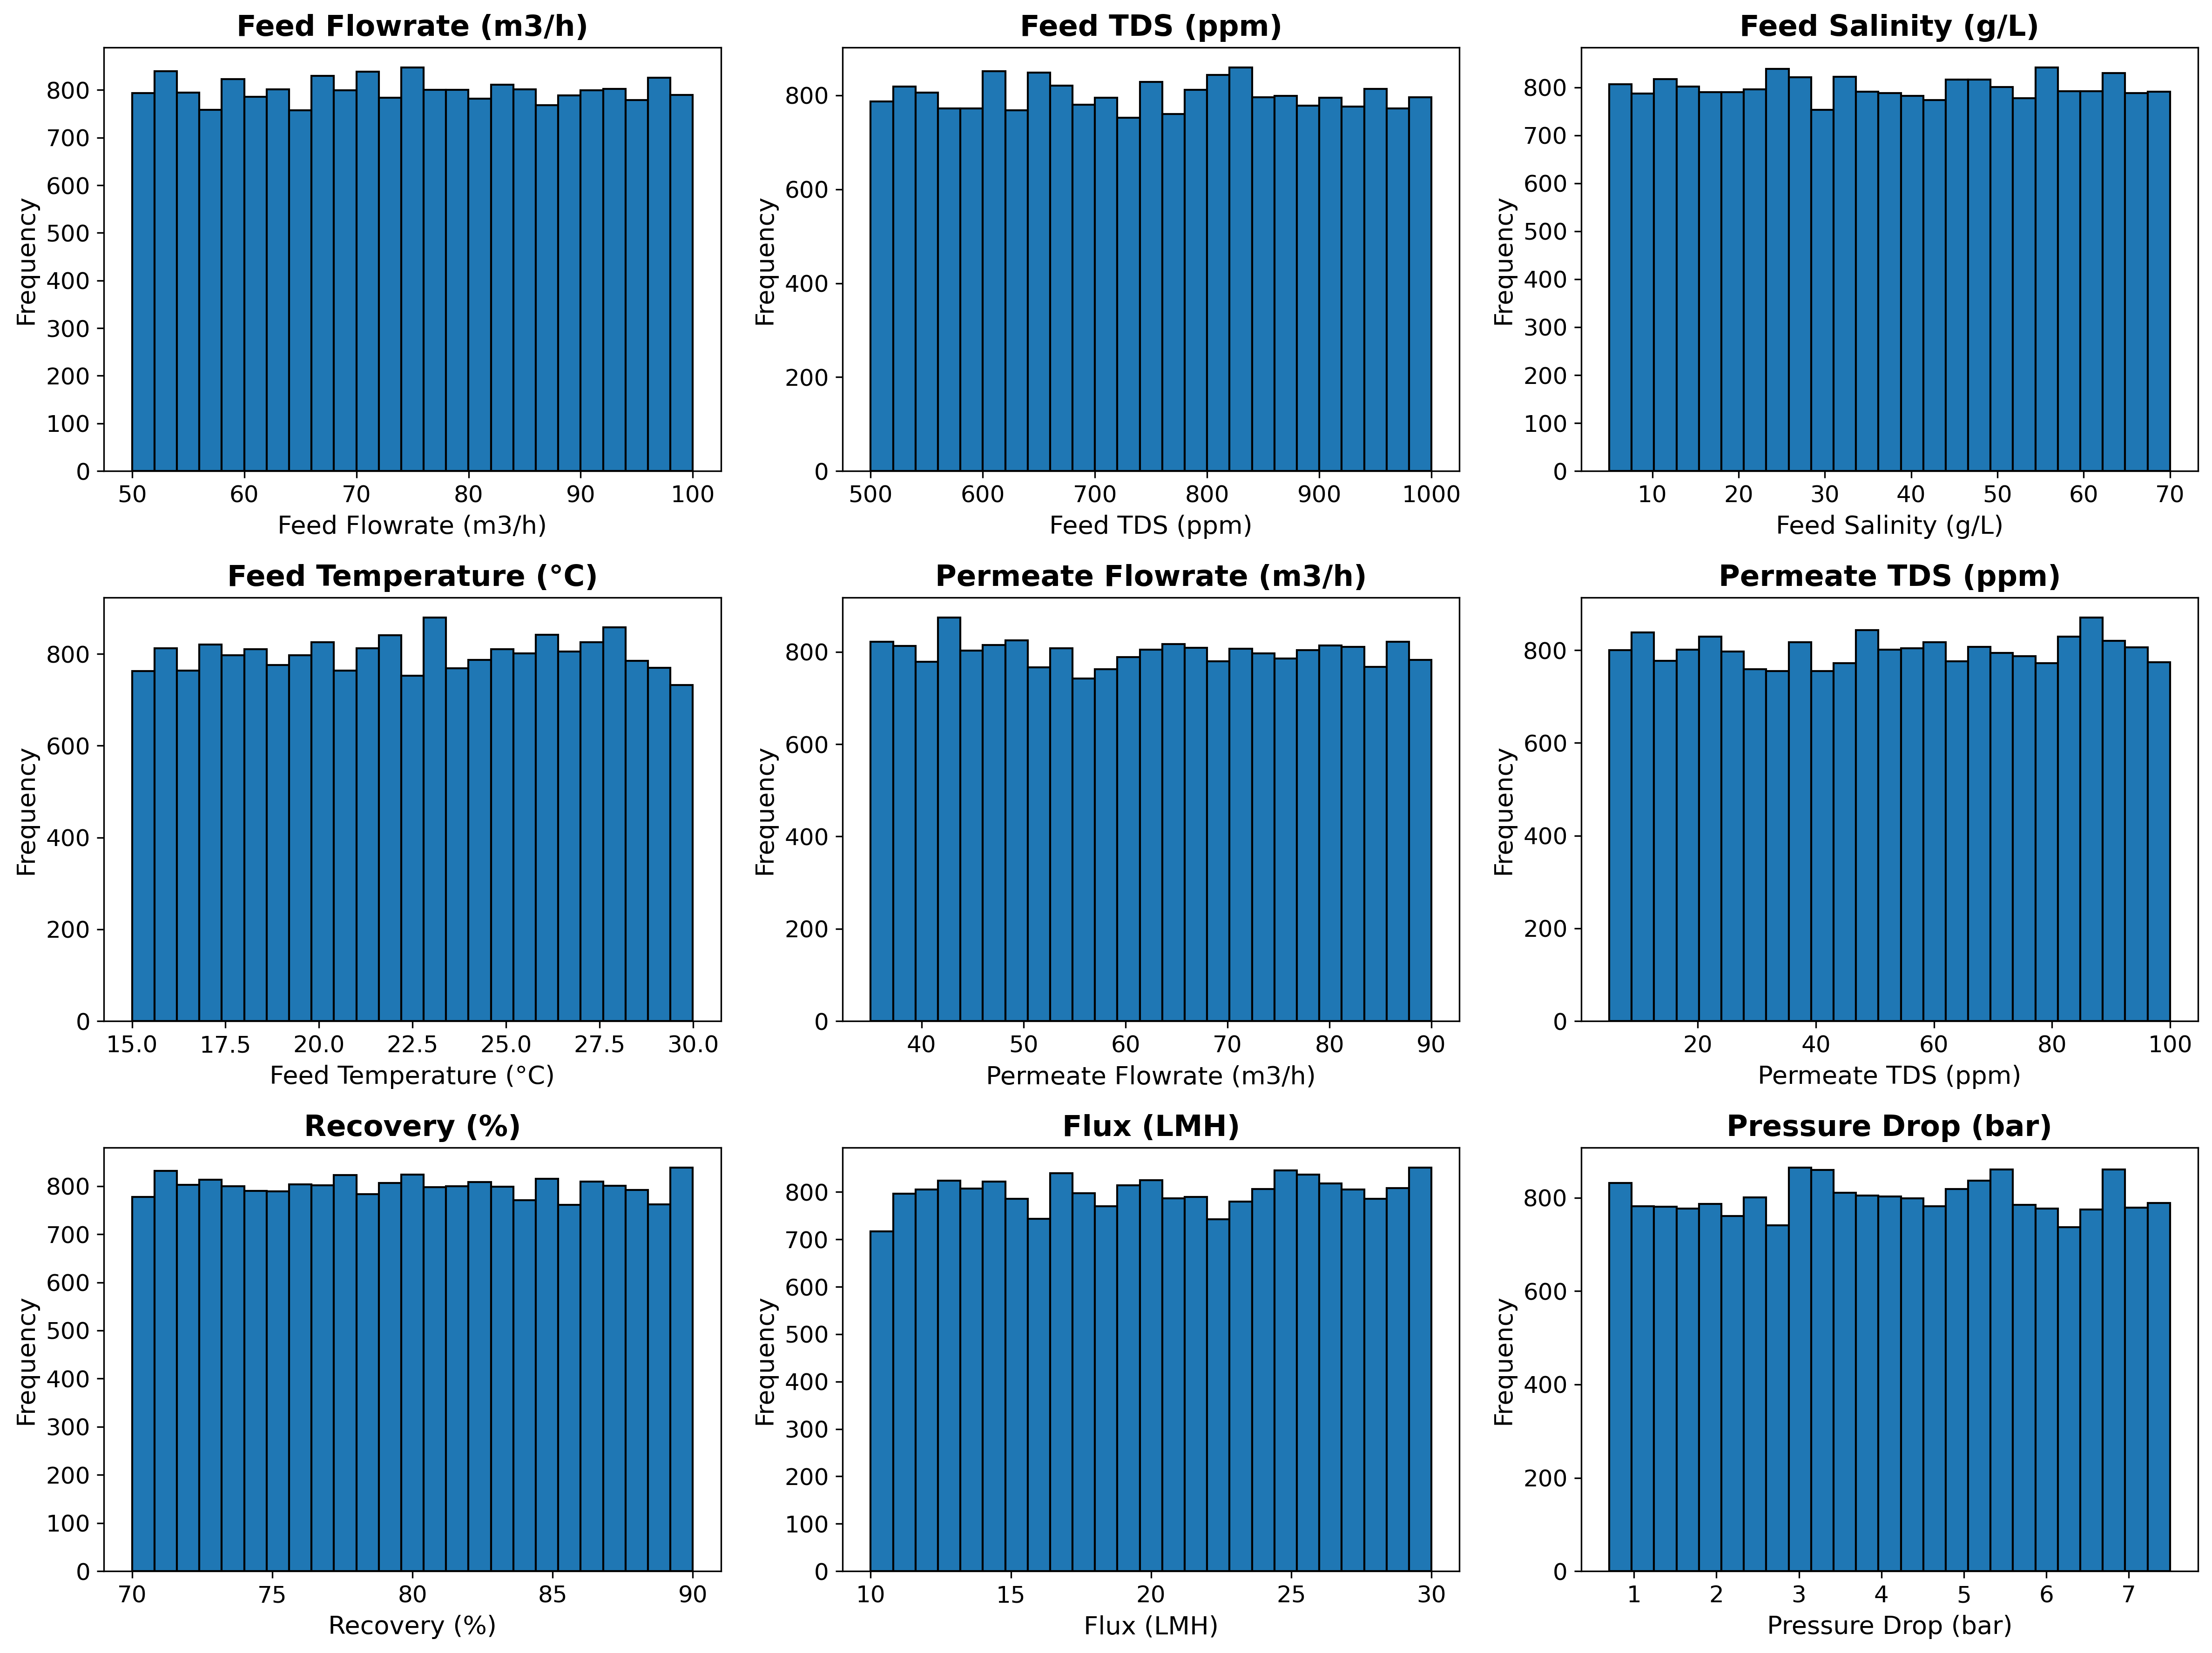

In [4]:
columns=df.columns

fig,axs=plt.subplots(3,3,figsize=(16,12))

axs=axs.flatten()

for i,col in enumerate(columns):

    axs[i].hist(df[col],
                bins=25,
                edgecolor='black')

    axs[i].set_title(col,fontweight='bold')
    axs[i].set_xlabel(col)
    axs[i].set_ylabel("Frequency")

plt.tight_layout()

plt.savefig("Figure1_Distributions.png",bbox_inches='tight')

plt.show()

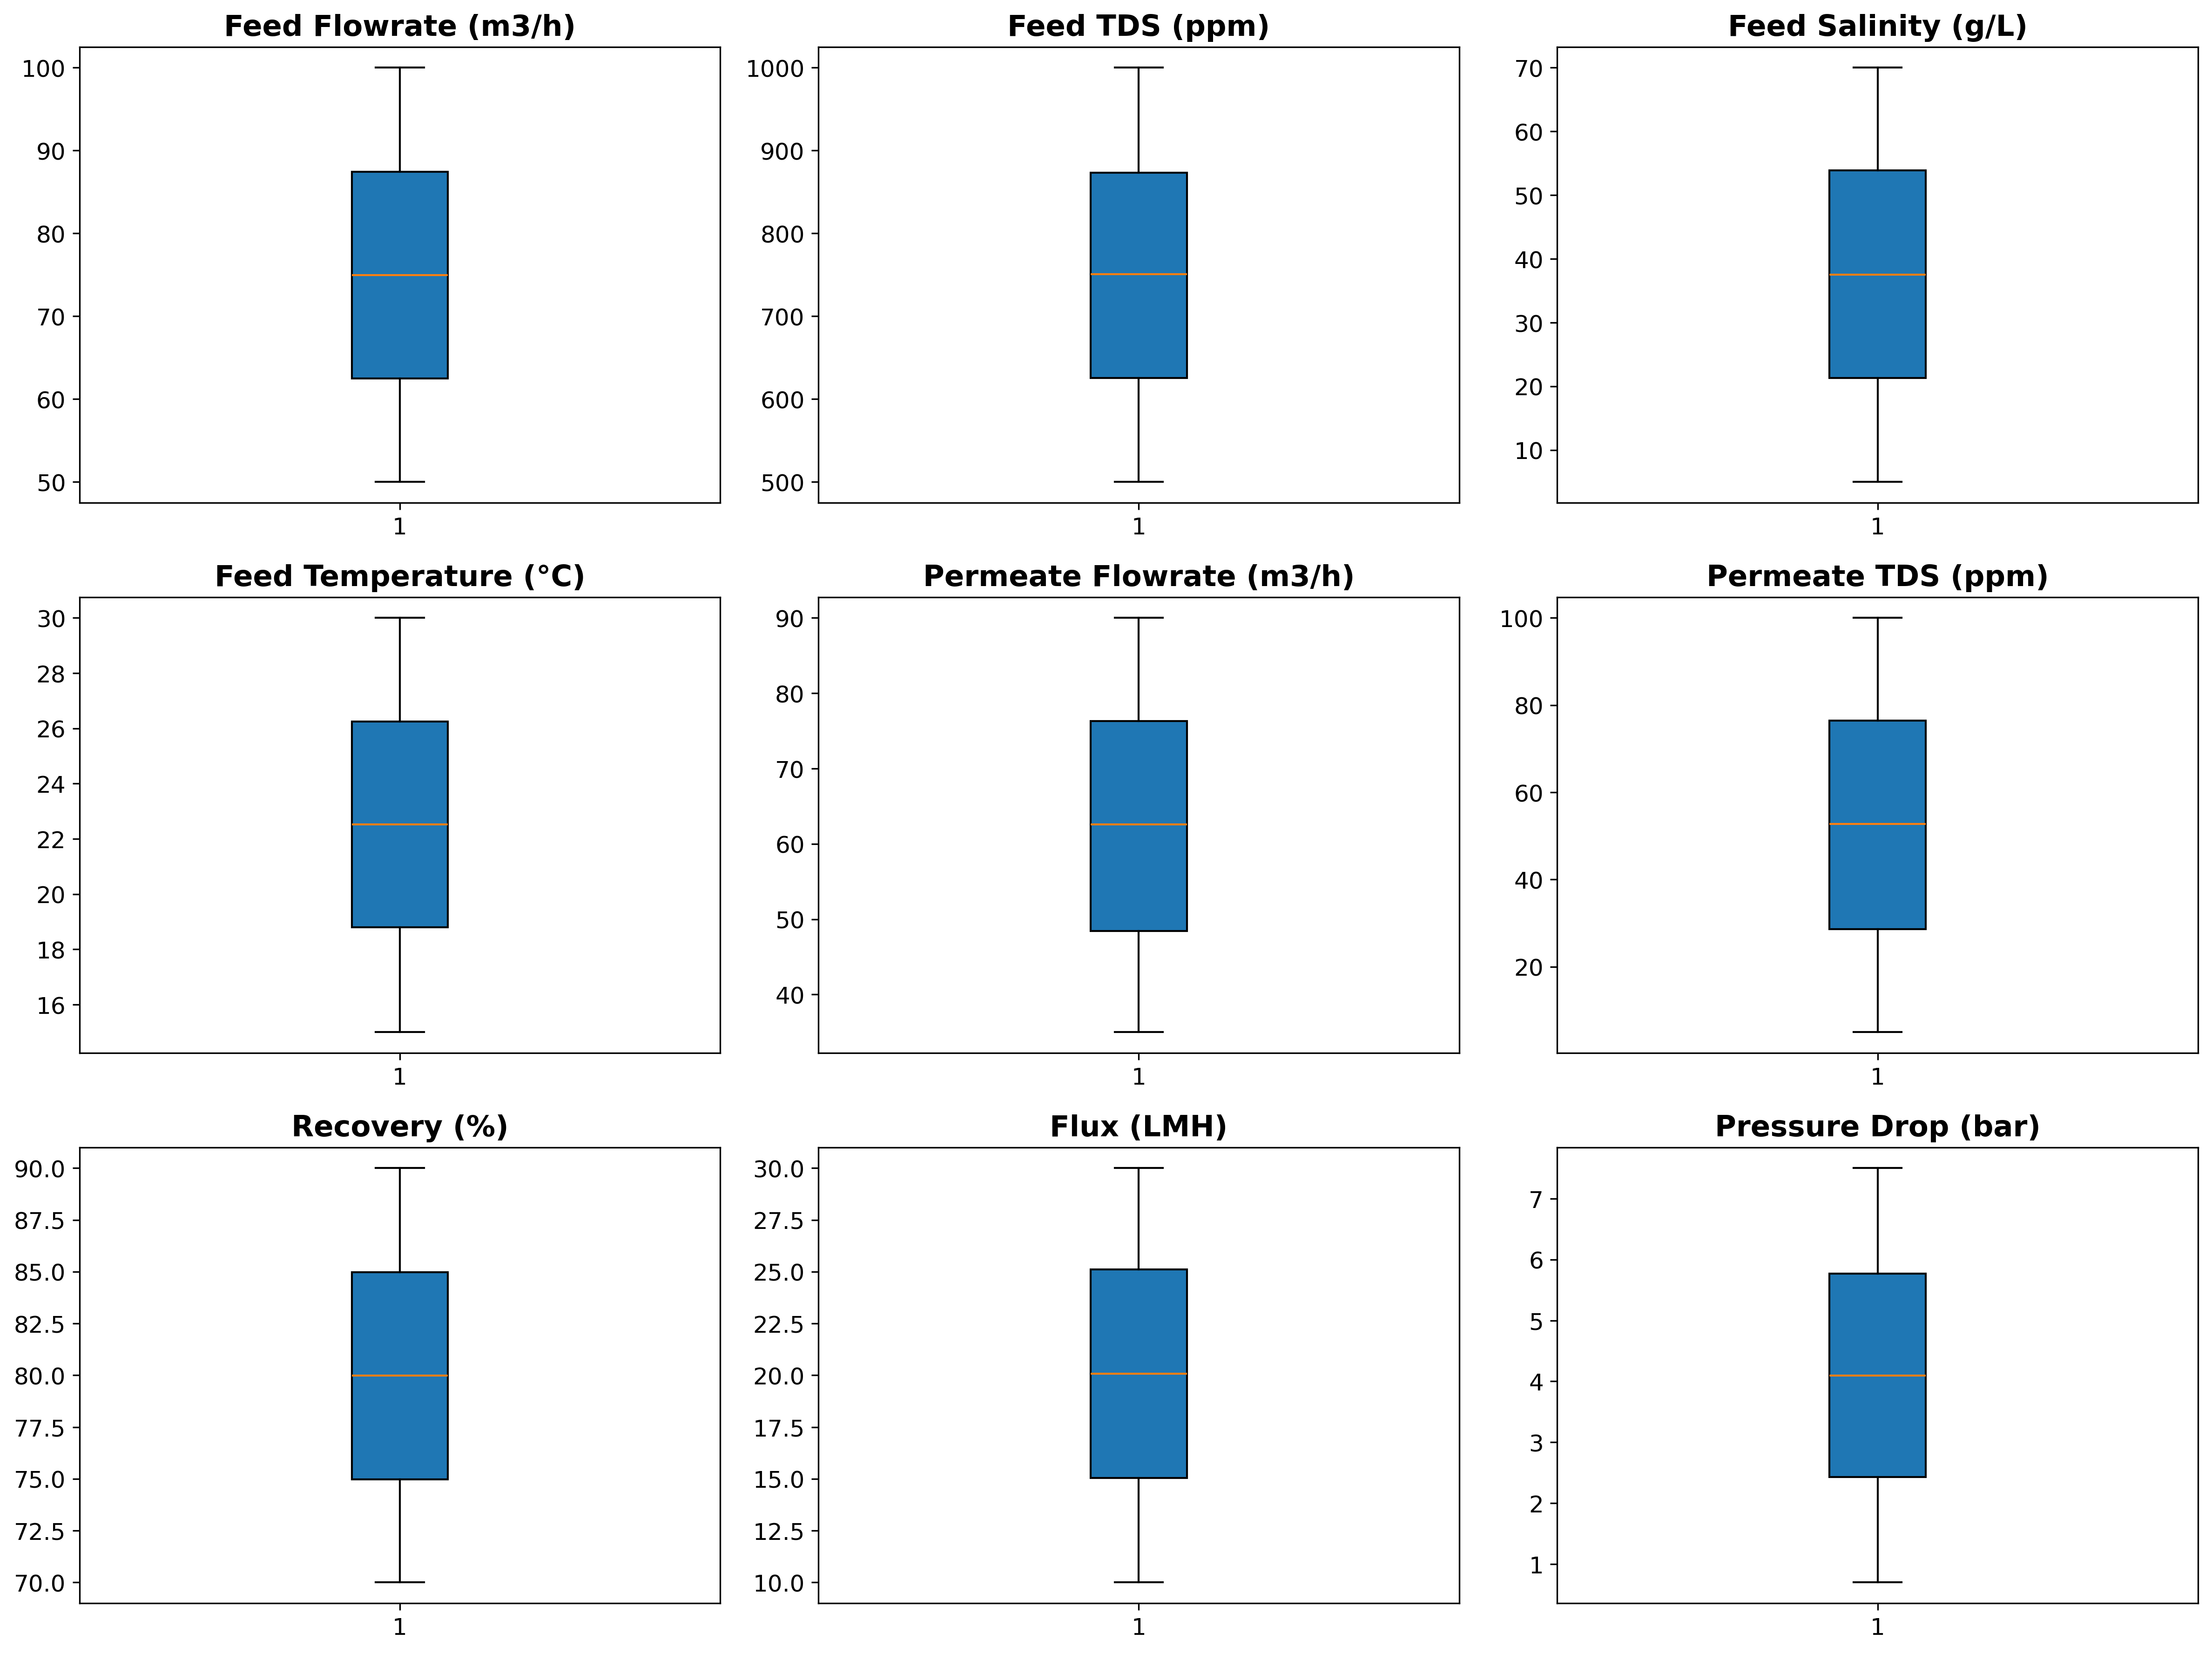

In [5]:
fig,axs=plt.subplots(3,3,figsize=(16,12))

axs=axs.flatten()

for i,col in enumerate(columns):

    axs[i].boxplot(df[col],
                   vert=True,
                   patch_artist=True)

    axs[i].set_title(col,fontweight='bold')

plt.tight_layout()

plt.savefig("Figure2_Boxplots.png",bbox_inches='tight')

plt.show()

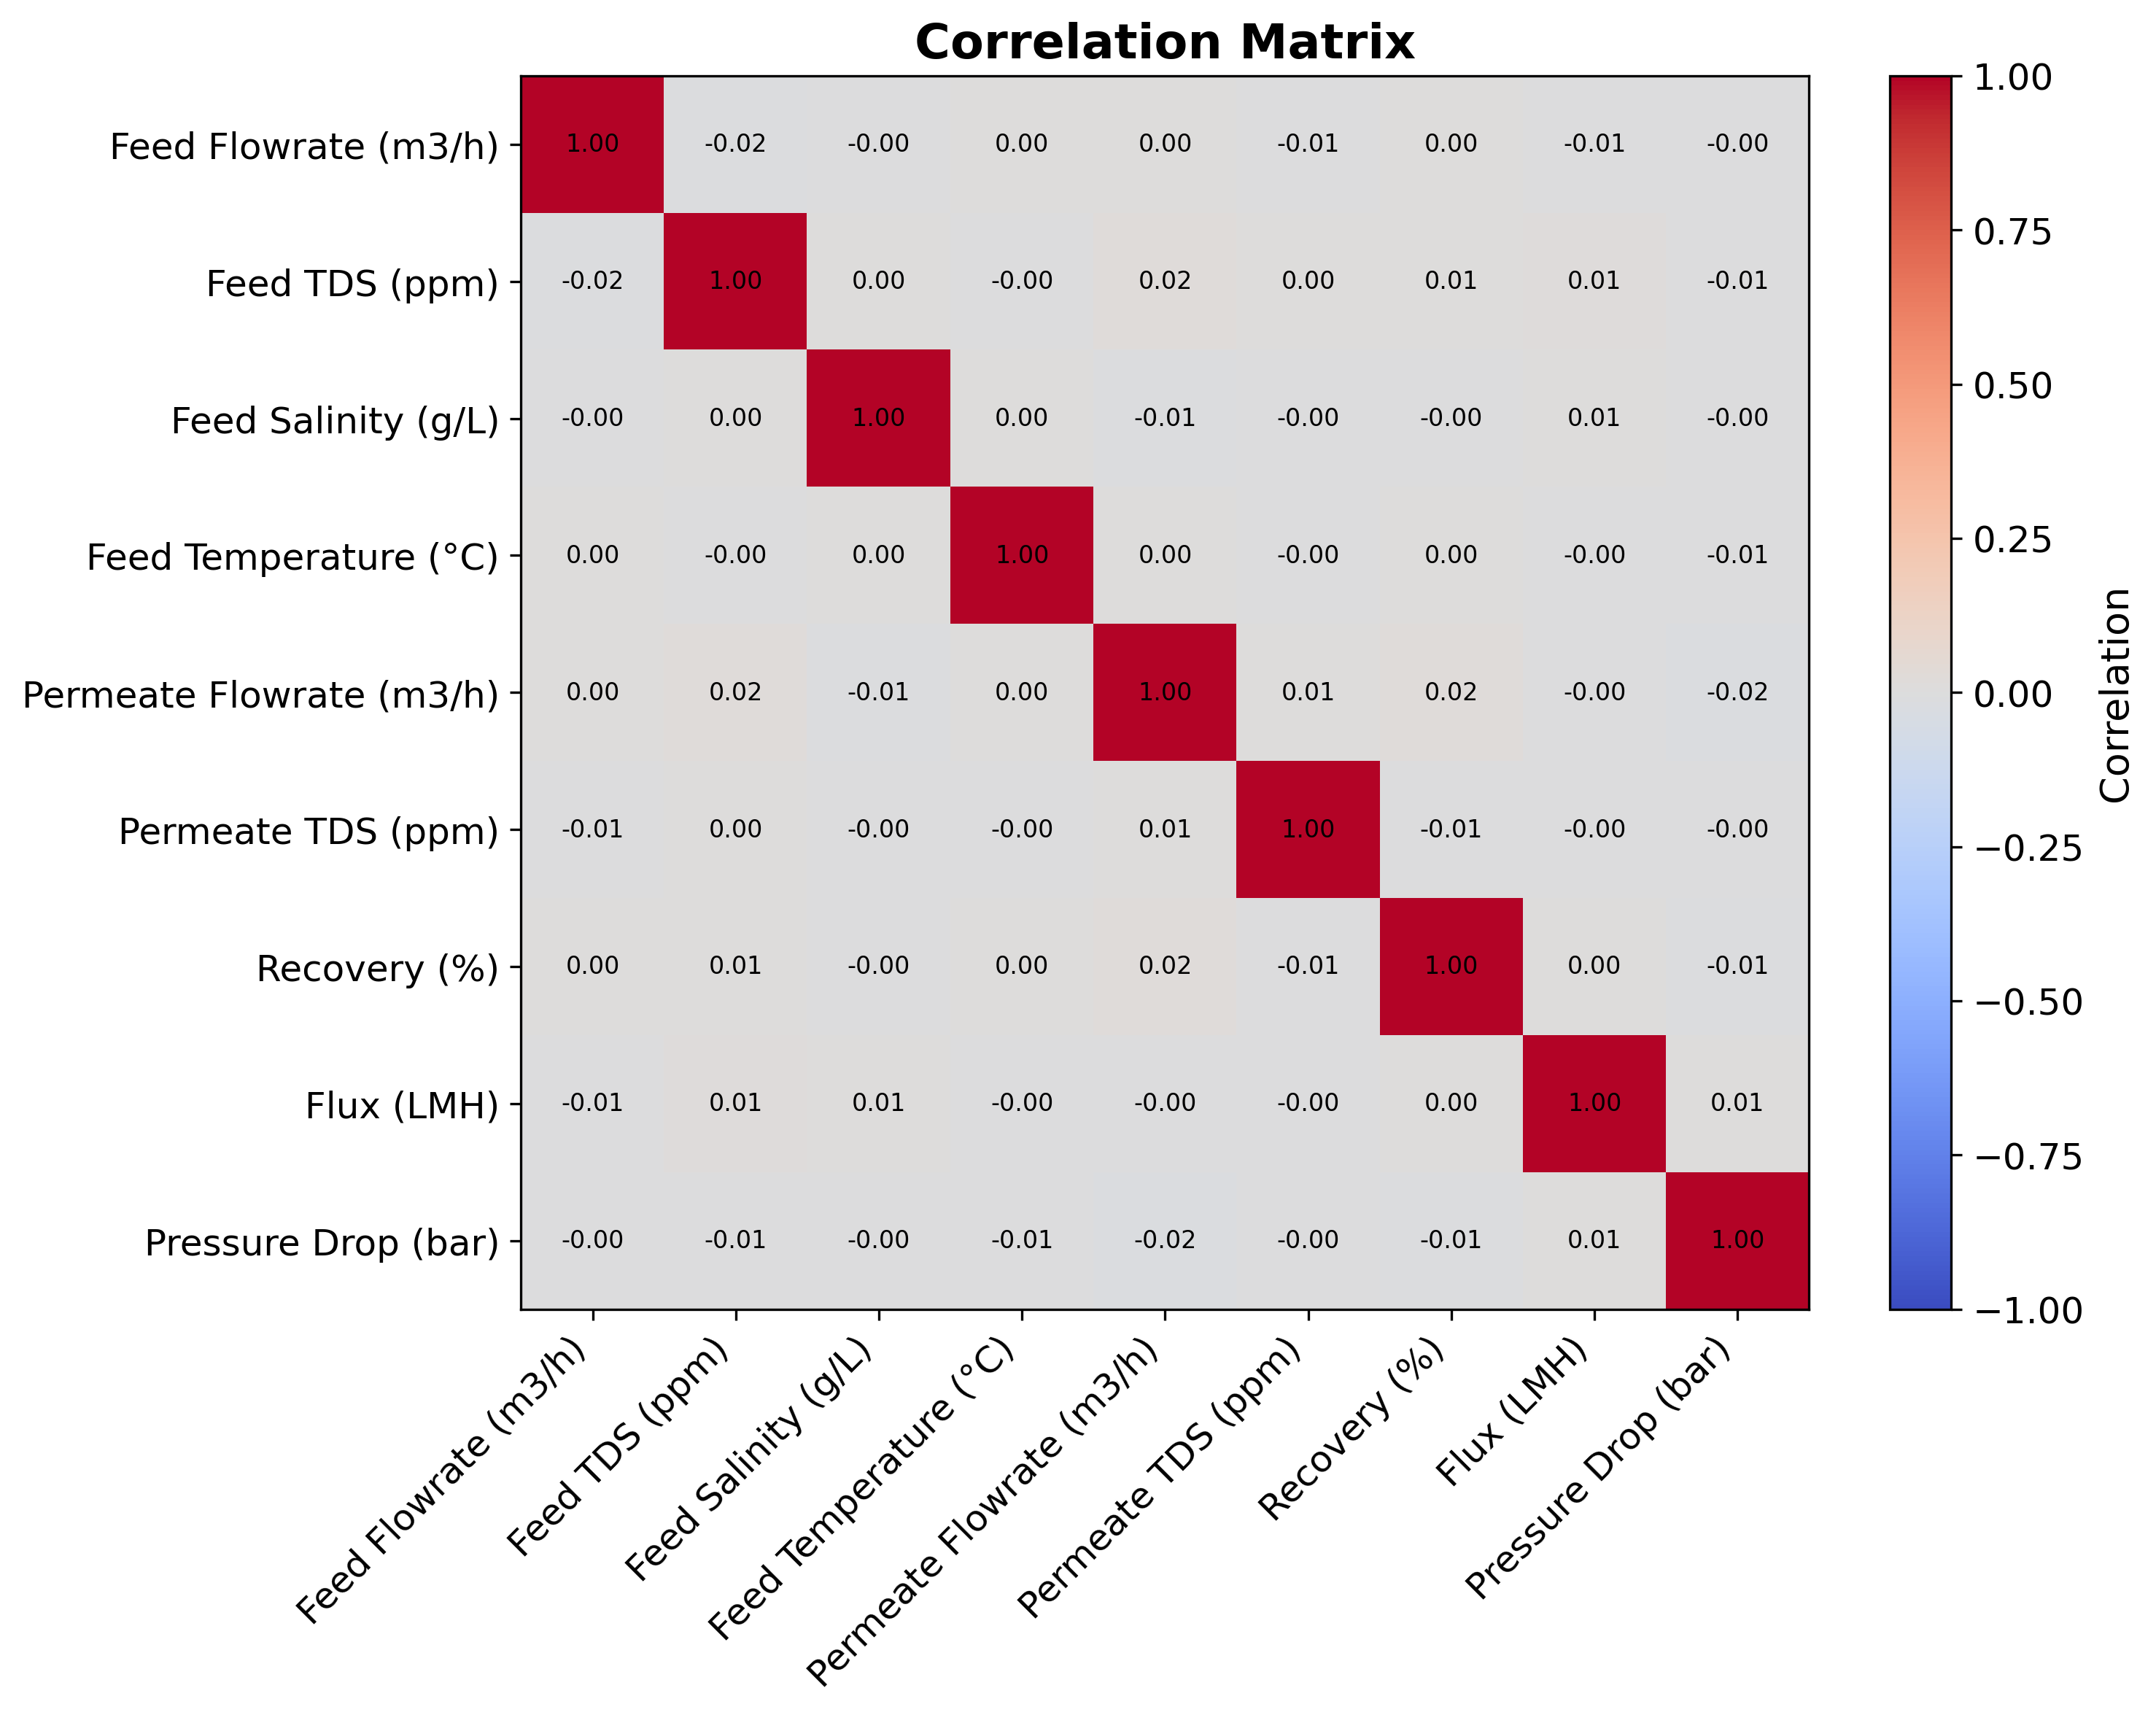

In [6]:
corr=df.corr(numeric_only=True)

fig,ax=plt.subplots(figsize=(10,8))

im=ax.imshow(corr,
             cmap='coolwarm',
             aspect='auto',
             vmin=-1,
             vmax=1)

ax.set_xticks(np.arange(len(corr.columns)))
ax.set_yticks(np.arange(len(corr.columns)))

ax.set_xticklabels(corr.columns,
                   rotation=45,
                   ha='right')

ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j,i,
                f"{corr.iloc[i,j]:.2f}",
                ha='center',
                va='center',
                fontsize=8)

cbar=plt.colorbar(im)
cbar.set_label("Correlation")

plt.title("Correlation Matrix",fontsize=16,fontweight='bold')

plt.tight_layout()

plt.savefig("Figure3_CorrelationHeatmap.png",bbox_inches='tight')

plt.show()

In [12]:
import os
import h5py
import numpy as np
import pandas as pd
import re

In [8]:
import os

ROOT_FOLDER = "RO_data"

count = 0

for root, dirs, files in os.walk(ROOT_FOLDER):

    for file in files:

        if file.endswith(".h5"):

            count += 1

            print(os.path.join(root,file))

print("\nTotal H5 files :",count)

RO_data\configuration1_interspacer0.75mm\HR_spacer_images\100_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\101_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\102_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\103_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\104_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\105_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\106_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\107_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\108_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\109_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\10_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\110_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\111_spa

In [9]:
master_data = []

In [13]:
# Research review: This cell computes descriptive statistics of stored HDF5 datasets. It does not validate CFD boundary conditions or numerical convergence.
for root, dirs, files in os.walk(ROOT_FOLDER):

    for file in files:

        if not file.endswith(".h5"):
            continue

        filepath = os.path.join(root, file)

        print("Reading :", filepath)

        # ---------------------------------------
        # Extract Configuration Number
        # ---------------------------------------

        config = None

        match = re.search(r'configuration(\d+)', root, re.IGNORECASE)

        if match:
            config = int(match.group(1))

        # ---------------------------------------
        # Extract Resolution
        # ---------------------------------------

        if "HR_spacer_images" in root:
            resolution = "HR"

        elif "LR_spacer_images" in root:
            resolution = "LR"

        else:
            resolution = "Unknown"

        # ---------------------------------------
        # Extract Image Number
        # ---------------------------------------

        image_match = re.search(r'(\d+)', file)

        if image_match:
            image_number = int(image_match.group(1))

        else:
            image_number = None

        # ---------------------------------------
        # Read HDF5 File
        # ---------------------------------------

        with h5py.File(filepath, 'r') as h5:

            def visitor(name, node):

                if isinstance(node, h5py.Dataset):

                    row = {}

                    row["Configuration"] = config

                    row["Resolution"] = resolution

                    row["Image_Number"] = image_number

                    row["File"] = file

                    row["Dataset"] = name

                    data = node[...]

                    row["Shape"] = str(data.shape)

                    row["Dimensions"] = len(data.shape)

                    row["Data_Type"] = str(data.dtype)

                    if np.issubdtype(data.dtype, np.number):

                        row["Mean"] = np.mean(data)

                        row["Std"] = np.std(data)

                        row["Min"] = np.min(data)

                        row["Max"] = np.max(data)

                        row["Median"] = np.median(data)

                        row["Variance"] = np.var(data)

                    master_data.append(row)

            h5.visititems(visitor)

Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\100_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\101_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\102_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\103_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\104_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\105_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\106_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\107_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\108_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\109_spacer_image.h5
Reading : RO_data\configuration1_interspacer0.75mm\HR_spacer_images\10_spacer_image.h5
Reading : RO_data\configuration1_

In [14]:
df = pd.DataFrame(master_data)

df = df.sort_values(
    by=[
        "Configuration",
        "Resolution",
        "Image_Number",
        "Dataset"
    ]
)

df.reset_index(drop=True, inplace=True)

df.to_excel("Extracted_HDF5_Data.xlsx", index=False)

print(df.head())

print()

print("Total Rows :", len(df))

   Configuration Resolution  Image_Number               File Dataset  \
0              1         HR             1  1_spacer_image.h5   Data0   
1              1         HR             1  1_spacer_image.h5   Data1   
2              1         HR             1  1_spacer_image.h5   Data2   
3              1         HR             1  1_spacer_image.h5   Data3   
4              1         HR             1  1_spacer_image.h5   Data4   

              Shape  Dimensions Data_Type          Mean           Std  \
0     (100, 1, 100)           3   float32  7.264732e+01  4.482197e+01   
1  (100, 1, 100, 3)           4   float32  3.288467e-02  7.785051e-02   
2     (100, 1, 100)           3   float32  1.449982e+07  8.943612e+06   
3     (100, 1, 100)           3   float32  1.449982e+07  8.943612e+06   
4     (100, 1, 100)           3   float32  7.716163e+02  4.759398e+02   

        Min           Max        Median      Variance  
0  0.000000  1.098369e+02  9.999937e+01  2.009009e+03  
1 -0.117216  3.6